# Actividad 5 - Entrenamiento y evaluación
Notebook de Machine Learning con MLflow.

# **Bloque 1 - Carga inicial del conjunto de datos.**


In [ ]:
import pandas as pd

# Dirección del archivo original en GitHub
ruta_principal = "https://raw.githubusercontent.com/madelgadom/Actividad5/main/datos/datos_ini/train.csv"

# Cargar el conjunto de datos
tabla1 = pd.read_csv(ruta_principal)

# Mostrar las primeras cinco observaciones
print("Primeros registros del dataset:")
print(tabla1.head())

Primeros registros del dataset:
   Unnamed: 0      id  Gender      Customer Type  Age   Type of Travel  \
0           0   70172    Male     Loyal Customer   13  Personal Travel   
1           1    5047    Male  disloyal Customer   25  Business travel   
2           2  110028  Female     Loyal Customer   26  Business travel   
3           3   24026  Female     Loyal Customer   25  Business travel   
4           4  119299    Male     Loyal Customer   61  Business travel   

      Class  Flight Distance  Inflight wifi service  \
0  Eco Plus              460                      3   
1  Business              235                      3   
2  Business             1142                      2   
3  Business              562                      2   
4  Business              214                      3   

   Departure/Arrival time convenient  ...  Inflight entertainment  \
0                                  4  ...                       5   
1                                  2  ...             


# **Bloque 2 - Análisis exploratorio de datos.**


In [ ]:

# Dimensiones del conjunto de datos
print("DIMENSIONES DEL DATASET")
print("Número de registros:", tabla1.shape[0])
print("Número de columnas:", tabla1.shape[1])

# Identificación de columnas y tipos de datos
print("\nINFORMACIÓN GENERAL")
tabla1.info()

# Identificación de valores nulos
print("\nVALORES NULOS POR COLUMNA")
print(tabla1.isnull().sum())

# Identificación de registros duplicados
print("\nREGISTROS DUPLICADOS")
print("Total de duplicados:", tabla1.duplicated().sum())

# Estadísticas descriptivas
print("\nESTADÍSTICAS DESCRIPTIVAS")
print(tabla1.describe(include="all").transpose())

# Distribución de la variable objetivo
print("\nDISTRIBUCIÓN DE SATISFACCIÓN")
print(tabla1["satisfaction"].value_counts())

print("\nPORCENTAJE POR CATEGORÍA")
print(tabla1["satisfaction"].value_counts(normalize=True) * 100)


DIMENSIONES DEL DATASET
Número de registros: 103904
Número de columnas: 25

INFORMACIÓN GENERAL
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  object 
 3   Customer Type                      103904 non-null  object 
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  object 
 6   Class                              103904 non-null  object 
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of 


# **Bloque 3 - Visualización y análisis de la distribución de los datos.**


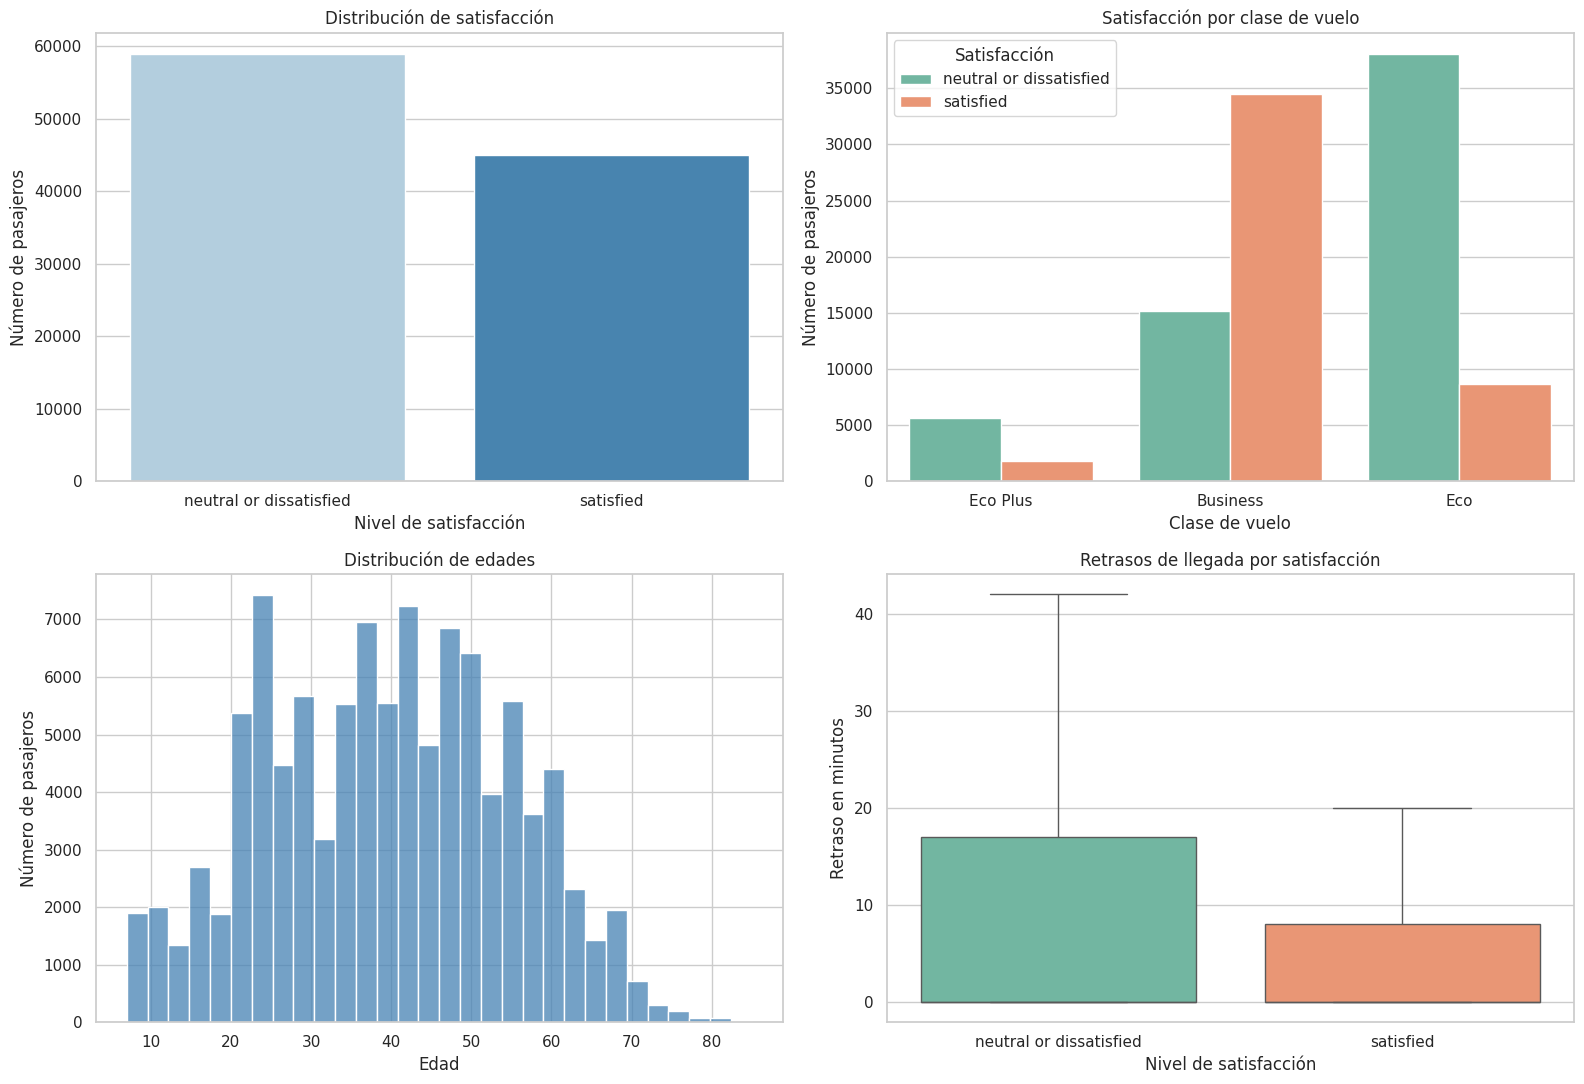

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general
sns.set_theme(style="whitegrid")

figura1, matriz1 = plt.subplots(2, 2, figsize=(16, 11))

# Gráfica 1: Distribución de satisfacción
sns.countplot(
    data=tabla1,
    x="satisfaction",
    hue="satisfaction",
    palette="Blues",
    legend=False,
    ax=matriz1[0, 0]
)

matriz1[0, 0].set_title("Distribución de satisfacción")
matriz1[0, 0].set_xlabel("Nivel de satisfacción")
matriz1[0, 0].set_ylabel("Número de pasajeros")

# Gráfica 2: Satisfacción según clase de vuelo
sns.countplot(
    data=tabla1,
    x="Class",
    hue="satisfaction",
    palette="Set2",
    ax=matriz1[0, 1]
)

matriz1[0, 1].set_title("Satisfacción por clase de vuelo")
matriz1[0, 1].set_xlabel("Clase de vuelo")
matriz1[0, 1].set_ylabel("Número de pasajeros")
matriz1[0, 1].legend(title="Satisfacción")

# Gráfica 3: Distribución de edades
sns.histplot(
    data=tabla1,
    x="Age",
    bins=30,
    color="steelblue",
    ax=matriz1[1, 0]
)

matriz1[1, 0].set_title("Distribución de edades")
matriz1[1, 0].set_xlabel("Edad")
matriz1[1, 0].set_ylabel("Número de pasajeros")

# Gráfica 4: Retrasos de llegada por satisfacción
sns.boxplot(
    data=tabla1,
    x="satisfaction",
    y="Arrival Delay in Minutes",
    hue="satisfaction",
    palette="Set2",
    legend=False,
    showfliers=False,
    ax=matriz1[1, 1]
)

matriz1[1, 1].set_title("Retrasos de llegada por satisfacción")
matriz1[1, 1].set_xlabel("Nivel de satisfacción")
matriz1[1, 1].set_ylabel("Retraso en minutos")

# Ajustar y mostrar las visualizaciones
plt.tight_layout()
plt.show()


# **Bloque 4 - Limpieza y preparación del conjunto de datos.**


In [ ]:
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Crear una copia para conservar los datos originales
tabla2 = tabla1.copy()

# Eliminar columnas de identificación
columnas_eliminar = ["Unnamed: 0", "id"]
tabla2 = tabla2.drop(columns=columnas_eliminar)

# Codificar la variable objetivo
tabla2["satisfaction"] = tabla2["satisfaction"].map({
    "neutral or dissatisfied": 0,
    "satisfied": 1
})

# Separar variables predictoras y variable objetivo
datos_principales = tabla2.drop(columns=["satisfaction"])
valor_principal = tabla2["satisfaction"]

# Identificar variables numéricas y categóricas
columnas_numericas = datos_principales.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

columnas_categoricas = datos_principales.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Preparación de variables numéricas
proceso_numerico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Preparación de variables categóricas
proceso_categorico = Pipeline(steps=[
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))
])

# Construir el transformador general
transformador_principal = ColumnTransformer(
    transformers=[
        ("numericas", proceso_numerico, columnas_numericas),
        ("categoricas", proceso_categorico, columnas_categoricas)
    ]
)

# Construir el proceso completo de preparación
proceso_principal = Pipeline(steps=[
    ("preparacion", transformador_principal)
])

# Mostrar resultados de la preparación
print("PREPARACIÓN DEL CONJUNTO DE DATOS")
print("Registros disponibles:", tabla2.shape[0])
print("Columnas después de eliminar identificadores:", tabla2.shape[1])

print("\nVARIABLES NUMÉRICAS")
print(columnas_numericas)

print("\nVARIABLES CATEGÓRICAS")
print(columnas_categoricas)

print("\nDISTRIBUCIÓN DE LA VARIABLE OBJETIVO")
print(valor_principal.value_counts())

print("\nVALORES NULOS IDENTIFICADOS")
print(datos_principales.isnull().sum()[
    datos_principales.isnull().sum() > 0
])

print("\nProceso de preparación configurado correctamente.")

PREPARACIÓN DEL CONJUNTO DE DATOS
Registros disponibles: 103904
Columnas después de eliminar identificadores: 23

VARIABLES NUMÉRICAS
['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Inflight service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes']

VARIABLES CATEGÓRICAS
['Gender', 'Customer Type', 'Type of Travel', 'Class']

DISTRIBUCIÓN DE LA VARIABLE OBJETIVO
satisfaction
0    58879
1    45025
Name: count, dtype: int64

VALORES NULOS IDENTIFICADOS
Arrival Delay in Minutes    310
dtype: int64

Proceso de preparación configurado correctamente.



# **Bloque 5 - Configuración de MLflow.**


In [ ]:
%pip install mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.1 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 91.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 101.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 62.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 15.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:

import sys
import subprocess
import os
import mlflow

# Instalar o actualizar MLflow
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "mlflow"
])

# Definir la ubicación del almacenamiento local
ruta_mlflow = "/content/mlruns"

# Crear el directorio de almacenamiento
os.makedirs(ruta_mlflow, exist_ok=True)

# Configurar el servidor de seguimiento local
mlflow.set_tracking_uri("sqlite:////content/mlflow.db")

# Crear o seleccionar el experimento principal
nombre_experimento = "Actividad5_Clasificacion_Pasajeros"
mlflow.set_experiment(nombre_experimento)

# Registrar un experimento de prueba
with mlflow.start_run(run_name="Validacion_Configuracion"):

    mlflow.log_param("actividad", "Clasificacion de pasajeros")
    mlflow.log_param("algoritmos", "Regresion Logistica y Random Forest")
    mlflow.log_param("registros", 103904)

    mlflow.log_metric("validacion_configuracion", 1.0)

    # Generar un artefacto de prueba
    ruta_artefacto = "/content/validacion_mlflow.txt"

    with open(ruta_artefacto, "w", encoding="utf-8") as archivo1:
        archivo1.write(
            "Configuracion de MLflow realizada correctamente.\n"
            "Actividad 5 - Clasificacion de pasajeros.\n"
        )

    mlflow.log_artifact(ruta_artefacto)

# Consultar el experimento registrado
experimento_principal = mlflow.get_experiment_by_name(
    nombre_experimento
)

tabla_experimentos = mlflow.search_runs(
    experiment_ids=[experimento_principal.experiment_id]
)

print("CONFIGURACIÓN DE MLFLOW")
print("Ubicación:", mlflow.get_tracking_uri())
print("Experimento:", nombre_experimento)
print("ID del experimento:", experimento_principal.experiment_id)

print("\nREGISTROS ENCONTRADOS")
print("Total de ejecuciones:", len(tabla_experimentos))

print("\nPARÁMETROS Y MÉTRICAS REGISTRADOS")
print(tabla_experimentos[
    [
        "tags.mlflow.runName",
        "params.algoritmos",
        "params.registros",
        "metrics.validacion_configuracion"
    ]
].to_string(index=False))

print("\nConfiguración y registro de prueba finalizados.")


2026/10/20 04:28:33 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/20 04:28:33 INFO mlflow.store.db.utils: Updating database tables
2026/10/20 04:28:36 INFO mlflow.tracking.fluent: Experiment with name 'Actividad5_Clasificacion_Pasajeros' does not exist. Creating a new experiment.


CONFIGURACIÓN DE MLFLOW
Ubicación: sqlite:////content/mlflow.db
Experimento: Actividad5_Clasificacion_Pasajeros
ID del experimento: 1

REGISTROS ENCONTRADOS
Total de ejecuciones: 1

PARÁMETROS Y MÉTRICAS REGISTRADOS
     tags.mlflow.runName                   params.algoritmos params.registros  metrics.validacion_configuracion
Validacion_Configuracion Regresion Logistica y Random Forest           103904                               1.0

Configuración y registro de prueba finalizados.




# **Bloque 6 - Entrenamiento de los modelos de clasificación.**


In [ ]:

# 6. Entrenamiento de los modelos de clasificación

import mlflow
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

# Configurar MLflow
mlflow.set_tracking_uri("sqlite:////content/mlflow.db")
mlflow.set_experiment("Actividad5_Clasificacion_Pasajeros")

# Definir los algoritmos
modelos_principales = {
    "Regresion_Logistica": LogisticRegression(
        max_iter=1000,
        solver="lbfgs",
        random_state=42
    ),
    "Random_Forest": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    )
}

# Configurar validación cruzada estratificada
validacion_principal = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Definir métricas de evaluación
metricas_principales = {
    "exactitud": "accuracy",
    "precision": "precision",
    "sensibilidad": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

# Almacenar los resultados
resultados_principales = []

# Entrenar y evaluar los modelos
for nombre_modelo, algoritmo_principal in modelos_principales.items():

    print("\nENTRENANDO:", nombre_modelo)

    # Integrar preparación y clasificación
    modelo_principal = Pipeline(steps=[
        ("preparacion", transformador_principal),
        ("clasificacion", algoritmo_principal)
    ])

    # Iniciar experimento en MLflow
    with mlflow.start_run(run_name=nombre_modelo):

        # Registrar parámetros
        mlflow.log_param("algoritmo", nombre_modelo)
        mlflow.log_param("particiones", 5)
        mlflow.log_param("registros", len(datos_principales))
        mlflow.log_param("semilla", 42)

        for parametro, valor in algoritmo_principal.get_params().items():
            if isinstance(valor, (str, int, float, bool)) or valor is None:
                mlflow.log_param(
                    "modelo_" + parametro,
                    str(valor)
                )

        # Ejecutar validación cruzada
        resultados_validacion = cross_validate(
            modelo_principal,
            datos_principales,
            valor_principal,
            cv=validacion_principal,
            scoring=metricas_principales,
            n_jobs=2,
            error_score="raise"
        )

        # Calcular y registrar métricas
        resultado_modelo = {"Modelo": nombre_modelo}

        for nombre_metrica in metricas_principales:

            valores_metrica = resultados_validacion[
                "test_" + nombre_metrica
            ]

            promedio_metrica = float(np.mean(valores_metrica))
            desviacion_metrica = float(np.std(valores_metrica))

            resultado_modelo[nombre_metrica] = promedio_metrica

            mlflow.log_metric(
                nombre_metrica + "_promedio",
                promedio_metrica
            )

            mlflow.log_metric(
                nombre_metrica + "_desviacion",
                desviacion_metrica
            )

        resultados_principales.append(resultado_modelo)

        print("Validación cruzada finalizada.")
        print("Métricas registradas en MLflow.")

# Construir tabla comparativa
tabla_resultados = pd.DataFrame(resultados_principales)

print("\nCOMPARACIÓN DE MODELOS")
print(tabla_resultados.round(4).to_string(index=False))



ENTRENANDO: Regresion_Logistica
Validación cruzada finalizada.
Métricas registradas en MLflow.

ENTRENANDO: Random_Forest
Validación cruzada finalizada.
Métricas registradas en MLflow.

COMPARACIÓN DE MODELOS
             Modelo  exactitud  precision  sensibilidad     f1  roc_auc
Regresion_Logistica     0.8752     0.8708        0.8361 0.8531   0.9267
      Random_Forest     0.9473     0.9460        0.9315 0.9387   0.9902




# **Bloque 7 - Optimización de hiperparámetros mediante Grid Search**


In [ ]:

# 7. Optimización de hiperparámetros mediante Grid Search

import mlflow
import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

# Configurar MLflow
mlflow.set_tracking_uri("sqlite:////content/mlflow.db")
mlflow.set_experiment("Actividad5_Clasificacion_Pasajeros")

# Definir las combinaciones de hiperparámetros
parametros_principales = {
    "Regresion_Logistica": {
        "clasificacion__C": [0.1, 1, 10],
        "clasificacion__max_iter": [1000]
    },
    "Random_Forest": {
        "clasificacion__n_estimators": [100, 200],
        "clasificacion__max_depth": [10, 20],
        "clasificacion__min_samples_split": [2, 5]
    }
}

# Configurar validación cruzada
validacion_ajuste = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Almacenar resultados y mejores modelos
resultados_ajuste = []
mejores_modelos = {}

# Optimizar ambos algoritmos
for nombre_modelo, algoritmo_principal in modelos_principales.items():

    print("\nOPTIMIZANDO:", nombre_modelo)

    # Construir el pipeline
    modelo_principal = Pipeline(steps=[
        ("preparacion", clone(transformador_principal)),
        ("clasificacion", clone(algoritmo_principal))
    ])

    # Configurar búsqueda de hiperparámetros
    busqueda_principal = GridSearchCV(
        estimator=modelo_principal,
        param_grid=parametros_principales[nombre_modelo],
        scoring="f1",
        cv=validacion_ajuste,
        n_jobs=2,
        refit=True,
        error_score="raise"
    )

    # Ejecutar optimización
    busqueda_principal.fit(
        datos_principales,
        valor_principal
    )

    # Guardar el mejor modelo
    mejores_modelos[nombre_modelo] = (
        busqueda_principal.best_estimator_
    )

    # Obtener resultados
    mejor_puntuacion = float(
        busqueda_principal.best_score_
    )

    mejores_parametros = (
        busqueda_principal.best_params_
    )

    # Registrar experimento en MLflow
    with mlflow.start_run(
        run_name=nombre_modelo + "_Optimizado"
    ):

        mlflow.log_param("algoritmo", nombre_modelo)
        mlflow.log_param("metodo", "GridSearchCV")
        mlflow.log_param("particiones", 3)
        mlflow.log_param("metrica_optimizacion", "f1")

        for parametro, valor in mejores_parametros.items():
            mlflow.log_param(parametro, valor)

        mlflow.log_metric(
            "mejor_f1_validacion",
            mejor_puntuacion
        )

        mlflow.log_metric(
            "combinaciones_evaluadas",
            len(busqueda_principal.cv_results_["params"])
        )

        # Guardar resultados de la búsqueda como artefacto
        tabla_busqueda = pd.DataFrame(
            busqueda_principal.cv_results_
        )

        ruta_resultados = (
            "/content/" + nombre_modelo + "_gridsearch.csv"
        )

        tabla_busqueda.to_csv(
            ruta_resultados,
            index=False
        )

        mlflow.log_artifact(ruta_resultados)

    # Almacenar resumen
    resultados_ajuste.append({
        "Modelo": nombre_modelo,
        "Mejor_F1": mejor_puntuacion,
        "Mejores_parametros": str(mejores_parametros)
    })

    print("Mejor F1:", round(mejor_puntuacion, 4))
    print("Mejores parámetros:", mejores_parametros)
    print("Resultados registrados en MLflow.")

# Generar tabla comparativa
tabla_ajuste = pd.DataFrame(resultados_ajuste)

print("\nRESULTADOS DE OPTIMIZACIÓN")
print(tabla_ajuste.to_string(index=False))

print("\nOptimización finalizada correctamente.")



OPTIMIZANDO: Regresion_Logistica
Mejor F1: 0.8532
Mejores parámetros: {'clasificacion__C': 10, 'clasificacion__max_iter': 1000}
Resultados registrados en MLflow.

OPTIMIZANDO: Random_Forest
Mejor F1: 0.9554
Mejores parámetros: {'clasificacion__max_depth': 20, 'clasificacion__min_samples_split': 2, 'clasificacion__n_estimators': 100}
Resultados registrados en MLflow.

RESULTADOS DE OPTIMIZACIÓN
             Modelo  Mejor_F1                                                                                          Mejores_parametros
Regresion_Logistica  0.853169                                                   {'clasificacion__C': 10, 'clasificacion__max_iter': 1000}
      Random_Forest  0.955438 {'clasificacion__max_depth': 20, 'clasificacion__min_samples_split': 2, 'clasificacion__n_estimators': 100}

Optimización finalizada correctamente.




# **Bloque 8 - Evaluación final de los modelos con datos de prueba**



EVALUANDO: Regresion_Logistica


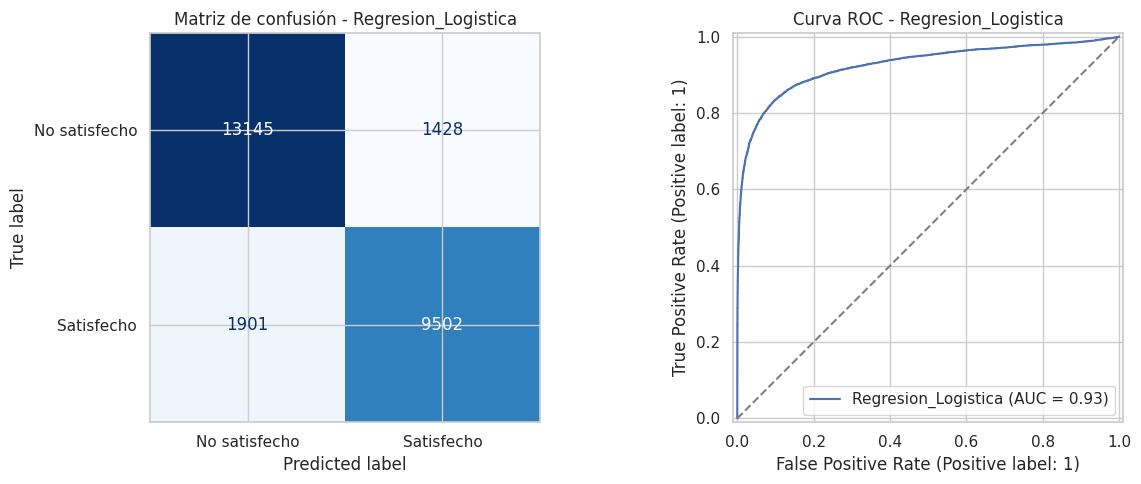

Exactitud: 0.8718
Precisión: 0.8694
Sensibilidad: 0.8333
F1: 0.8509
ROC-AUC: 0.9256
Resultados registrados en MLflow.

EVALUANDO: Random_Forest


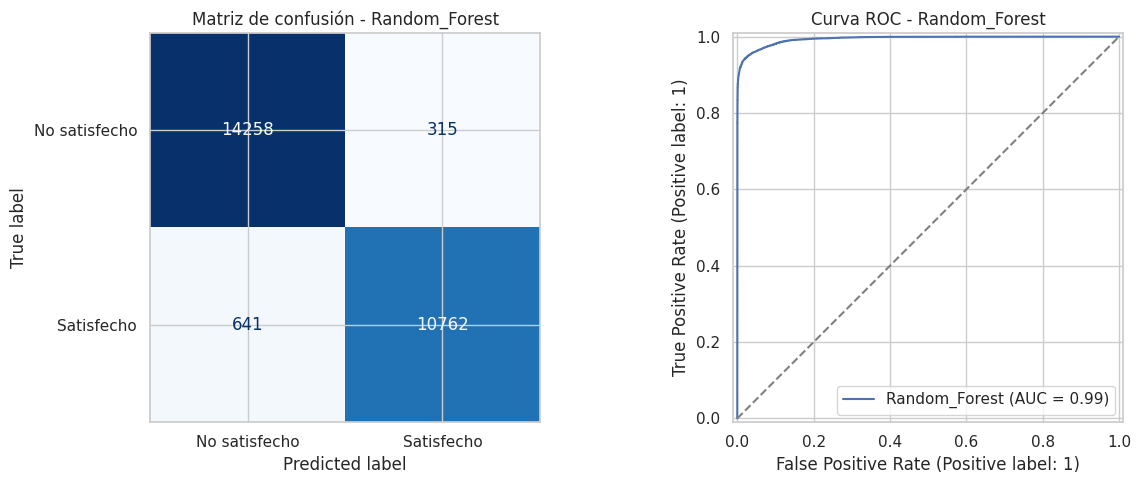

Exactitud: 0.9632
Precisión: 0.9716
Sensibilidad: 0.9438
F1: 0.9575
ROC-AUC: 0.994
Resultados registrados en MLflow.

COMPARACIÓN FINAL DE MODELOS
             Modelo  Exactitud  Precision  Sensibilidad     F1  ROC_AUC
Regresion_Logistica     0.8718     0.8694        0.8333 0.8509   0.9256
      Random_Forest     0.9632     0.9716        0.9438 0.9575   0.9940

Evaluación final completada correctamente.


In [ ]:

# 8. Evaluación final de los modelos con datos de prueba

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Configurar MLflow
mlflow.set_tracking_uri("sqlite:////content/mlflow.db")
mlflow.set_experiment("Actividad5_Clasificacion_Pasajeros")

# Cargar datos de prueba desde GitHub
ruta_prueba = (
    "https://raw.githubusercontent.com/madelgadom/Actividad5/"
    "main/datos/datos_ini/test.csv"
)

tabla_prueba = pd.read_csv(ruta_prueba)

# Eliminar identificadores
tabla_prueba = tabla_prueba.drop(
    columns=["Unnamed: 0", "id"]
)

# Codificar la variable objetivo
tabla_prueba["satisfaction"] = tabla_prueba["satisfaction"].map({
    "neutral or dissatisfied": 0,
    "satisfied": 1
})

# Separar variables predictoras y variable objetivo
datos_prueba = tabla_prueba.drop(columns=["satisfaction"])
valores_prueba = tabla_prueba["satisfaction"]

# Validar estructura de los datos
if valores_prueba.isnull().any():
    raise ValueError("Existen categorías no reconocidas en satisfaction.")

if set(datos_prueba.columns) != set(datos_principales.columns):
    raise ValueError("Las columnas de prueba no coinciden con entrenamiento.")

datos_prueba = datos_prueba[datos_principales.columns]

# Crear carpeta para las evidencias
ruta_evidencias = "/content/evidencias_mlflow"
os.makedirs(ruta_evidencias, exist_ok=True)

# Almacenar resultados
resultados_finales = []

# Evaluar los modelos optimizados
for nombre_modelo, modelo_principal in mejores_modelos.items():

    print("\nEVALUANDO:", nombre_modelo)

    # Obtener predicciones
    predicciones = modelo_principal.predict(datos_prueba)

    probabilidades = modelo_principal.predict_proba(
        datos_prueba
    )[:, 1]

    # Calcular métricas
    exactitud = accuracy_score(valores_prueba, predicciones)
    precision = precision_score(valores_prueba, predicciones)
    sensibilidad = recall_score(valores_prueba, predicciones)
    puntuacion_f1 = f1_score(valores_prueba, predicciones)
    area_roc = roc_auc_score(valores_prueba, probabilidades)

    # Almacenar resultados
    resultados_finales.append({
        "Modelo": nombre_modelo,
        "Exactitud": exactitud,
        "Precision": precision,
        "Sensibilidad": sensibilidad,
        "F1": puntuacion_f1,
        "ROC_AUC": area_roc
    })

    # Generar visualizaciones
    figura1, matriz1 = plt.subplots(1, 2, figsize=(13, 5))

    # Matriz de confusión
    matriz_confusion = confusion_matrix(
        valores_prueba,
        predicciones,
        labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=matriz_confusion,
        display_labels=["No satisfecho", "Satisfecho"]
    ).plot(
        ax=matriz1[0],
        cmap="Blues",
        colorbar=False
    )

    matriz1[0].set_title(
        "Matriz de confusión - " + nombre_modelo
    )

    # Curva ROC
    RocCurveDisplay.from_predictions(
        valores_prueba,
        probabilidades,
        ax=matriz1[1],
        name=nombre_modelo
    )

    matriz1[1].plot(
        [0, 1], [0, 1],
        linestyle="--",
        color="gray"
    )

    matriz1[1].set_title(
        "Curva ROC - " + nombre_modelo
    )

    plt.tight_layout()

    # Guardar visualización
    ruta_grafica = os.path.join(
        ruta_evidencias,
        nombre_modelo + "_evaluacion.png"
    )

    figura1.savefig(
        ruta_grafica,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(figura1)

    # Registrar evaluación en MLflow
    with mlflow.start_run(
        run_name=nombre_modelo + "_Evaluacion_Final"
    ):

        mlflow.log_param("algoritmo", nombre_modelo)
        mlflow.log_param("conjunto", "test.csv")
        mlflow.log_param("registros_prueba", len(datos_prueba))

        mlflow.log_metric("exactitud_test", exactitud)
        mlflow.log_metric("precision_test", precision)
        mlflow.log_metric("sensibilidad_test", sensibilidad)
        mlflow.log_metric("f1_test", puntuacion_f1)
        mlflow.log_metric("roc_auc_test", area_roc)

        # Registrar gráfica
        mlflow.log_artifact(ruta_grafica)

        # Registrar modelo entrenado
        mlflow.sklearn.log_model(
          sk_model=modelo_principal,
          name="modelo_clasificacion",
          skops_trusted_types=[
            "numpy.dtype",
            "sklearn.compose._column_transformer._RemainderColsList",
            "sklearn.tree._tree.Tree"
          ]
        )

    print("Exactitud:", round(exactitud, 4))
    print("Precisión:", round(precision, 4))
    print("Sensibilidad:", round(sensibilidad, 4))
    print("F1:", round(puntuacion_f1, 4))
    print("ROC-AUC:", round(area_roc, 4))
    print("Resultados registrados en MLflow.")

# Construir tabla comparativa final
tabla_final = pd.DataFrame(resultados_finales)

print("\nCOMPARACIÓN FINAL DE MODELOS")
print(tabla_final.round(4).to_string(index=False))

# Guardar tabla comparativa
ruta_tabla = os.path.join(
    ruta_evidencias,
    "comparacion_final.csv"
)

tabla_final.to_csv(ruta_tabla, index=False)

# Registrar tabla comparativa en MLflow
with mlflow.start_run(run_name="Comparacion_Final_Modelos"):
    mlflow.log_artifact(ruta_tabla)

print("\nEvaluación final completada correctamente.")




# **Bloque 9 - Comparación estadística del desempeño de los modelos**



COMPARACIÓN ESTADÍSTICA DE MODELOS

MATRIZ DE CONTINGENCIA
[[22445   202]
 [ 2575   754]]

RESULTADOS DE MCNEMAR
Estadístico: 2026.0655
Valor p: 0.0
Nivel de significancia: 0.05

CONCLUSIÓN ESTADÍSTICA
Existe una diferencia estadísticamente significativa entre los modelos.


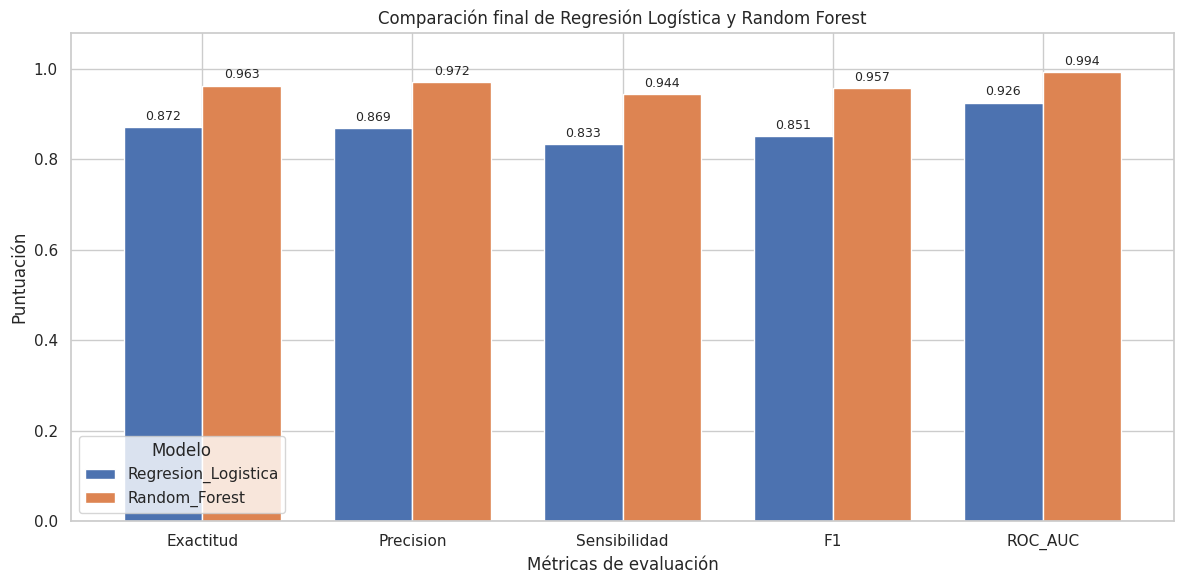


Resultados estadísticos registrados en MLflow.
Comparación estadística finalizada correctamente.


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow

from statsmodels.stats.contingency_tables import mcnemar

# Configurar MLflow
mlflow.set_tracking_uri("sqlite:////content/mlflow.db")
mlflow.set_experiment("Actividad5_Clasificacion_Pasajeros")

# Recuperar los modelos optimizados
modelo_logistico = mejores_modelos["Regresion_Logistica"]
modelo_bosque = mejores_modelos["Random_Forest"]

# Generar predicciones sobre los mismos datos de prueba
predicciones_logisticas = modelo_logistico.predict(datos_prueba)
predicciones_bosque = modelo_bosque.predict(datos_prueba)

# Identificar predicciones correctas e incorrectas
aciertos_logisticos = predicciones_logisticas == valores_prueba
aciertos_bosque = predicciones_bosque == valores_prueba

# Construir tabla de contingencia
matriz_principal = np.array([
    [
        np.sum(aciertos_logisticos & aciertos_bosque),
        np.sum(aciertos_logisticos & ~aciertos_bosque)
    ],
    [
        np.sum(~aciertos_logisticos & aciertos_bosque),
        np.sum(~aciertos_logisticos & ~aciertos_bosque)
    ]
])

# Aplicar prueba estadística de McNemar
resultado_estadistico = mcnemar(
    matriz_principal,
    exact=False,
    correction=True
)

valor_estadistico = float(resultado_estadistico.statistic)
valor_probabilidad = float(resultado_estadistico.pvalue)
nivel_significancia = 0.05

# Mostrar resultados estadísticos
print("COMPARACIÓN ESTADÍSTICA DE MODELOS")

print("\nMATRIZ DE CONTINGENCIA")
print(matriz_principal)

print("\nRESULTADOS DE MCNEMAR")
print("Estadístico:", round(valor_estadistico, 4))
print("Valor p:", valor_probabilidad)
print("Nivel de significancia:", nivel_significancia)

if valor_probabilidad < nivel_significancia:
    conclusion_principal = (
        "Existe una diferencia estadísticamente significativa "
        "entre los modelos."
    )
else:
    conclusion_principal = (
        "No existe evidencia suficiente de una diferencia "
        "estadísticamente significativa entre los modelos."
    )

print("\nCONCLUSIÓN ESTADÍSTICA")
print(conclusion_principal)

# Preparar métricas para comparación visual
columnas_metricas = [
    "Exactitud",
    "Precision",
    "Sensibilidad",
    "F1",
    "ROC_AUC"
]

tabla_comparativa = tabla_final.set_index("Modelo")[
    columnas_metricas
].transpose()

# Generar gráfica comparativa
figura1, matriz_grafica = plt.subplots(figsize=(12, 6))

tabla_comparativa.plot(
    kind="bar",
    ax=matriz_grafica,
    width=0.75
)

matriz_grafica.set_title(
    "Comparación final de Regresión Logística y Random Forest"
)
matriz_grafica.set_xlabel("Métricas de evaluación")
matriz_grafica.set_ylabel("Puntuación")
matriz_grafica.set_ylim(0, 1.08)
matriz_grafica.legend(title="Modelo")
matriz_grafica.tick_params(axis="x", rotation=0)

for grupo_barras in matriz_grafica.containers:
    matriz_grafica.bar_label(
        grupo_barras,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

plt.tight_layout()

# Guardar evidencias
ruta_evidencias = "/content/evidencias_mlflow"
os.makedirs(ruta_evidencias, exist_ok=True)

ruta_grafica = os.path.join(
    ruta_evidencias,
    "comparacion_estadistica.png"
)

ruta_tabla = os.path.join(
    ruta_evidencias,
    "comparacion_estadistica.csv"
)

figura1.savefig(
    ruta_grafica,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
plt.close(figura1)

# Crear tabla con resultados estadísticos
tabla_estadistica = pd.DataFrame([{
    "Estadistico_McNemar": valor_estadistico,
    "Valor_p": valor_probabilidad,
    "Nivel_significancia": nivel_significancia,
    "Diferencia_significativa": (
        valor_probabilidad < nivel_significancia
    ),
    "Solo_logistica_correcta": int(matriz_principal[0, 1]),
    "Solo_bosque_correcto": int(matriz_principal[1, 0])
}])

tabla_estadistica.to_csv(ruta_tabla, index=False)

# Registrar resultados en MLflow
with mlflow.start_run(run_name="Comparacion_Estadistica"):

    mlflow.log_param("prueba", "McNemar")
    mlflow.log_param("nivel_significancia", nivel_significancia)
    mlflow.log_param("modelos", "Regresion Logistica vs Random Forest")

    mlflow.log_metric(
        "estadistico_mcnemar",
        valor_estadistico
    )

    mlflow.log_metric(
        "valor_p_mcnemar",
        valor_probabilidad
    )

    mlflow.log_metric(
        "diferencia_significativa",
        int(valor_probabilidad < nivel_significancia)
    )

    mlflow.log_artifact(ruta_grafica)
    mlflow.log_artifact(ruta_tabla)

print("\nResultados estadísticos registrados en MLflow.")
print("Comparación estadística finalizada correctamente.")





# **Bloque 10 - Verificación y recopilación de evidencias en MLflow**


In [ ]:

# 10. Verificación y recopilación de evidencias en MLflow

import os
import json
import shutil
import pandas as pd
import mlflow

from mlflow.tracking import MlflowClient
from IPython.display import display

# Configurar conexión con MLflow
mlflow.set_tracking_uri("sqlite:////content/mlflow.db")

nombre_experimento = "Actividad5_Clasificacion_Pasajeros"

experimento_principal = mlflow.get_experiment_by_name(
    nombre_experimento
)

if experimento_principal is None:
    raise ValueError("No se encontró el experimento en MLflow.")

# Crear cliente de seguimiento
cliente_principal = MlflowClient()

# Consultar ejecuciones registradas
tabla_experimentos = mlflow.search_runs(
    experiment_ids=[experimento_principal.experiment_id],
    output_format="pandas"
)

print("VERIFICACIÓN DE EXPERIMENTOS EN MLFLOW")
print("Experimento:", nombre_experimento)
print("Total de ejecuciones:", len(tabla_experimentos))

# Crear directorio de evidencias
ruta_evidencias = "/content/evidencias_mlflow"
os.makedirs(ruta_evidencias, exist_ok=True)

# Seleccionar información relevante
columnas_principales = [
    "run_id",
    "tags.mlflow.runName",
    "status",
    "start_time",
    "metrics.exactitud_test",
    "metrics.precision_test",
    "metrics.sensibilidad_test",
    "metrics.f1_test",
    "metrics.roc_auc_test",
    "metrics.mejor_f1_validacion",
    "metrics.estadistico_mcnemar",
    "metrics.valor_p_mcnemar"
]

columnas_disponibles = [
    columna for columna in columnas_principales
    if columna in tabla_experimentos.columns
]

tabla_resumen = tabla_experimentos[
    columnas_disponibles
].copy()

print("\nRESUMEN DE EJECUCIONES")
display(tabla_resumen)

# Verificar parámetros, métricas y artefactos
registros_verificacion = []

for identificador in tabla_experimentos["run_id"]:

    ejecucion_principal = cliente_principal.get_run(
        identificador
    )

    artefactos_principales = cliente_principal.list_artifacts(
        identificador
    )

    nombre_ejecucion = ejecucion_principal.data.tags.get(
        "mlflow.runName", "Sin nombre"
    )

    registros_verificacion.append({
        "Ejecucion": nombre_ejecucion,
        "ID": identificador,
        "Parametros": len(ejecucion_principal.data.params),
        "Metricas": len(ejecucion_principal.data.metrics),
        "Artefactos": len(artefactos_principales),
        "Estado": ejecucion_principal.info.status
    })

tabla_verificacion = pd.DataFrame(
    registros_verificacion
)

print("\nVERIFICACIÓN DE REGISTROS")
display(tabla_verificacion)

# Exportar tablas de evidencia
ruta_resumen = os.path.join(
    ruta_evidencias,
    "resumen_experimentos.csv"
)

ruta_verificacion = os.path.join(
    ruta_evidencias,
    "verificacion_mlflow.csv"
)

tabla_resumen.to_csv(ruta_resumen, index=False)
tabla_verificacion.to_csv(ruta_verificacion, index=False)

# Exportar detalles de cada ejecución
detalles_experimentos = []

for identificador in tabla_experimentos["run_id"]:

    ejecucion_principal = cliente_principal.get_run(
        identificador
    )

    detalles_experimentos.append({
        "id": identificador,
        "nombre": ejecucion_principal.data.tags.get(
            "mlflow.runName", "Sin nombre"
        ),
        "estado": ejecucion_principal.info.status,
        "parametros": ejecucion_principal.data.params,
        "metricas": ejecucion_principal.data.metrics,
        "artefactos": [
            {
                "ruta": elemento.path,
                "directorio": elemento.is_dir
            }
            for elemento in cliente_principal.list_artifacts(
                identificador
            )
        ]
    })

ruta_detalles = os.path.join(
    ruta_evidencias,
    "detalles_experimentos.json"
)

with open(ruta_detalles, "w", encoding="utf-8") as archivo1:
    json.dump(
        detalles_experimentos,
        archivo1,
        indent=4,
        ensure_ascii=False
    )

# Comprimir evidencias para su descarga
ruta_comprimida = shutil.make_archive(
    "/content/evidencias_actividad5",
    "zip",
    ruta_evidencias
)

print("\nARCHIVOS GENERADOS")
print("Resumen:", ruta_resumen)
print("Verificación:", ruta_verificacion)
print("Detalles:", ruta_detalles)
print("Archivo comprimido:", ruta_comprimida)

print("\nVerificación de MLflow finalizada correctamente.")


VERIFICACIÓN DE EXPERIMENTOS EN MLFLOW
Experimento: Actividad5_Clasificacion_Pasajeros
Total de ejecuciones: 14

RESUMEN DE EJECUCIONES


,run_id,tags.mlflow.runName,status,start_time,metrics.exactitud_test,metrics.precision_test,metrics.sensibilidad_test,metrics.f1_test,metrics.roc_auc_test,metrics.mejor_f1_validacion,metrics.estadistico_mcnemar,metrics.valor_p_mcnemar
0,7bfb40faf087414298f40df7dca17bed,Comparacion_Estadistica,FINISHED,2026-10-20 05:00:24.873000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,2026.065538,0.0
1,c345d95392c343269cfbf13dd1b769f1,Comparacion_Final_Modelos,FINISHED,2026-10-20 04:54:04.663000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,604b272bff674802b7fc7c9e0839795d,Random_Forest_Evaluacion_Final,FINISHED,2026-10-20 04:53:57.758000+00:00,0.963197,0.971563,0.943787,0.957473,0.994039,NaN,NaN,NaN
3,1f56ca0133c945bb820333feaff28cdf,Regresion_Logistica_Evaluacion_Final,FINISHED,2026-10-20 04:53:50.029000+00:00,0.871843,0.869350,0.833289,0.850938,0.925596,NaN,NaN,NaN
4,69f50a7168b041a9a12db5aadbccc69d,Random_Forest_Evaluacion_Final,FAILED,2026-10-20 04:51:55.482000+00:00,0.963197,0.971563,0.943787,0.957473,0.994039,NaN,NaN,NaN
5,5b6155e742674e7cb83088e7c03700b0,Regresion_Logistica_Evaluacion_Final,FINISHED,2026-10-20 04:51:43.673000+00:00,0.871843,0.869350,0.833289,0.850938,0.925596,NaN,NaN,NaN
6,9731a1d2c7b64aae90aa2f131cf2ecc9,Regresion_Logistica_Evaluacion_Final,FAILED,2026-10-20 04:47:32.190000+00:00,0.871843,0.869350,0.833289,0.850938,0.925596,NaN,NaN,NaN
7,d8d20c1b54cf46a2bab2c3cdb0aec17a,Random_Forest_Optimizado,FINISHED,2026-10-20 04:42:54.353000+00:00,NaN,NaN,NaN,NaN,NaN,0.955438,NaN,NaN
8,064952ed5ee64729a5137a6e2055e373,Regresion_Logistica_Optimizado,FINISHED,2026-10-20 04:37:57.367000+00:00,NaN,NaN,NaN,NaN,NaN,0.853169,NaN,NaN
9,2171e4d2610b4077afbfb1312a39c867,Random_Forest,FINISHED,2026-10-20 04:32:59.724000+00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



VERIFICACIÓN DE REGISTROS


,Ejecucion,ID,Parametros,Metricas,Artefactos,Estado
0,Comparacion_Estadistica,7bfb40faf087414298f40df7dca17bed,3,3,2,FINISHED
1,Comparacion_Final_Modelos,c345d95392c343269cfbf13dd1b769f1,0,0,1,FINISHED
2,Random_Forest_Evaluacion_Final,604b272bff674802b7fc7c9e0839795d,3,5,1,FINISHED
3,Regresion_Logistica_Evaluacion_Final,1f56ca0133c945bb820333feaff28cdf,3,5,1,FINISHED
4,Random_Forest_Evaluacion_Final,69f50a7168b041a9a12db5aadbccc69d,3,5,1,FAILED
5,Regresion_Logistica_Evaluacion_Final,5b6155e742674e7cb83088e7c03700b0,3,5,1,FINISHED
6,Regresion_Logistica_Evaluacion_Final,9731a1d2c7b64aae90aa2f131cf2ecc9,3,5,1,FAILED
7,Random_Forest_Optimizado,d8d20c1b54cf46a2bab2c3cdb0aec17a,7,2,1,FINISHED
8,Regresion_Logistica_Optimizado,064952ed5ee64729a5137a6e2055e373,6,2,1,FINISHED
9,Random_Forest,2171e4d2610b4077afbfb1312a39c867,23,10,0,FINISHED



ARCHIVOS GENERADOS
Resumen: /content/evidencias_mlflow/resumen_experimentos.csv
Verificación: /content/evidencias_mlflow/verificacion_mlflow.csv
Detalles: /content/evidencias_mlflow/detalles_experimentos.json
Archivo comprimido: /content/evidencias_actividad5.zip

Verificación de MLflow finalizada correctamente.



# **Ejecucion GIT**


In [2]:
!git clone https://github.com/madelgadom/Actividad5.git

Cloning into 'Actividad5'...
remote: Enumerating objects: 80, done.
remote: Counting objects: 100% (80/80), done.
remote: Compressing objects: 100% (71/71), done.
remote: Total 80 (delta 20), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (80/80), 3.16 MiB | 3.73 MiB/s, done.
Resolving deltas: 100% (20/20), done.


In [3]:
%pip install pandas numpy scikit-learn mlflow skops

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 3.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.1/51.1 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.3/44.3 kB 688.2 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 95.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.1/4.1 MB 103.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 61.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.7/148.7 kB 10.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 268.7/268.7 kB 18.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 228.4/228.4 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 136.5/136.5 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [4]:
!cd /content/Actividad5 && python fuentes/train.py

2026/10/20 15:35:50 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/20 15:35:50 INFO mlflow.store.db.utils: Updating database tables
2026/10/20 15:35:54 INFO mlflow.tracking.fluent: Experiment with name 'Actividad5_Clasificacion_Pasajeros' does not exist. Creating a new experiment.

ENTRENANDO: Regresion_Logistica
Entrenamiento y evaluación finalizados.
F1: 0.8509
ROC-AUC: 0.9256
Resultados registrados en MLflow.

ENTRENANDO: Random_Forest
Entrenamiento y evaluación finalizados.
F1: 0.9575
ROC-AUC: 0.994
Resultados registrados en MLflow.

COMPARACIÓN FINAL DE MODELOS
             Modelo  Exactitud  Precision  Sensibilidad     F1  ROC_AUC
Regresion_Logistica     0.8718     0.8694        0.8333 0.8509   0.9256
      Random_Forest     0.9632     0.9716        0.9438 0.9575   0.9940

Proceso completado correctamente.
